In [1]:
# 0. Preparando o Ambiente

import pandas as pd
import matplotlib.pyplot as plt

# 1. Carregar os Dados

df = pd.read_csv("../data/ecommerce_site_reviews.csv")

# 2. Analise de Status de Entrega

delivery_summary = df['delivery_status'].value_counts()

print("--- Status das Entregas ---")
print(delivery_summary)

# 3. Classificação Simples de Sentimento baseada na Nota

def categorizar_sentimento(rating):
    if rating >= 4:
        return 'Positivo'
    elif rating == 3:
        return 'Neutro'
    else:
        return 'Negativo'

df['sentimento'] = df['review_rating'].apply(categorizar_sentimento)





--- Status das Entregas ---
delivery_status
No Prazo     69
Atrasado     23
Cancelado     8
Name: count, dtype: int64


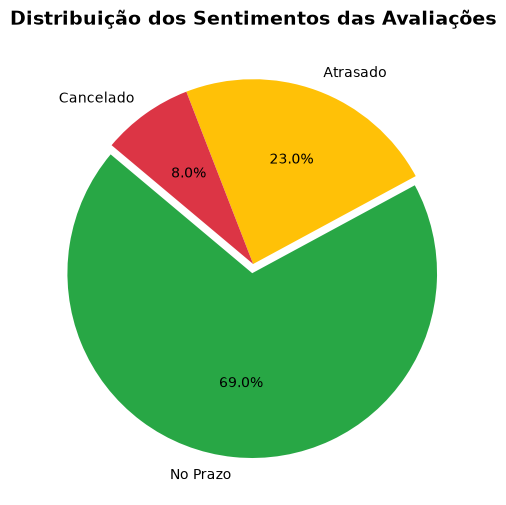

In [2]:
# 4. Criando um gráfico de pizza

plt.figure(figsize=(6, 6))
plt.pie(
    delivery_summary,
    labels=delivery_summary.index, 
    autopct='%1.1f%%',                  # Exibe a porcentagem com 1 casa decimal
    startangle=140,                      # Roda o gráfico para um melhor ângulo
    colors=['#28a745', '#ffc107', '#dc3545'], # Verde (Positivo), Amarelo (Neutro), Vermelho (Negativo)
    explode=(0.05, 0, 0)                 # Destaca a primeira fatia
)

plt.title("Distribuição dos Sentimentos das Avaliações", fontsize=14, fontweight='bold')
plt.show()

In [5]:
# 5. Filtrar Apenas os Pedidos Atrasados

df_atrasados = df[df['delivery_status'] == 'Atrasado'][
    ['order_id', 'customer_id', 'delivery_days', 'review_rating', 'sentimento', 'review_text']
].copy()

# 6. Renomear as Colunas

df_atrasados = df_atrasados.rename(columns={
    'order_id': 'ID do Pedido',
    'customer_id': 'ID do Cliente',
    'delivery_days': 'Dias de Entrega',
    'review_rating': 'Nota',
    'sentimento': 'Sentimento',
    'review_text': 'Comentário do Cliente'
})

# 7. Trata os Decimais da Coluna de Dias de Entrega

df_atrasados['Dias de Entrega'] = df_atrasados['Dias de Entrega'].astype(int)

def colorir_sentimento(val):
    if val == 'Positivo':
        return 'background-color: #d4edda; color: #155724; font-weight: bold;'
    elif val == 'Neutro':
        return 'background-color: #fff3cd; color: #856404; font-weight: bold;'
    elif val == 'Negativo':
        return 'background-color: #f8d7da; color: #721c24; font-weight: bold;'
    return ''

# 8. Aplicar Cores e Exibir

df_atrasados.head(10).style \
    .map(colorir_sentimento, subset=['Sentimento']) \
    .background_gradient(cmap='YlOrRd', subset=['Dias de Entrega']) \
    .set_caption("<b>Detalhamento dos Pedidos Atrasados e Avaliações</b>") \
    .set_properties(**{'text-align': 'left'}) \
    .hide(axis='index')

ID do Pedido,ID do Cliente,Dias de Entrega,Nota,Sentimento,Comentário do Cliente
ORD-1006,CUST-800,11,1,Negativo,"Entrega muito atrasada, fiquei insatisfeita."
ORD-1011,CUST-314,8,1,Negativo,"Péssimo atendimento, demorou demais para chegar."
ORD-1014,CUST-187,12,1,Negativo,"Entrega muito atrasada, fiquei insatisfeita."
ORD-1017,CUST-971,14,3,Neutro,"O produto é bom, mas a entrega atrasou um pouco."
ORD-1018,CUST-763,7,1,Negativo,"Péssimo atendimento, demorou demais para chegar."
ORD-1019,CUST-230,15,1,Negativo,"Péssimo atendimento, demorou demais para chegar."
ORD-1020,CUST-761,12,1,Negativo,"Entrega muito atrasada, fiquei insatisfeita."
ORD-1024,CUST-591,6,1,Negativo,"Entrega muito atrasada, fiquei insatisfeita."
ORD-1030,CUST-260,13,2,Negativo,Demorou mais do que o informado na compra.
ORD-1032,CUST-413,6,1,Negativo,"Entrega muito atrasada, fiquei insatisfeita."


In [7]:
# 9. Filtrar Apenas os Pedidos Cancelados

df_cancelados = df[df['delivery_status'] == 'Cancelado'][
    ['order_id', 'customer_id', 'delivery_days', 'review_rating', 'sentimento', 'review_text']
].copy()

# 10. Preencher os Valores NaN de 'delivery_days' com Base na Análise do Texto do Comentário

def identificar_origem_cancelamento(row):
    texto = str(row['review_text']).lower()
    if 'acabei cancelando' in texto or 'cancelei' in texto or 'desisti' in texto:
        return 'Cliente Cancelou'
    else:
        return 'Cancelamos'

df_cancelados['delivery_days'] = df_cancelados.apply(identificar_origem_cancelamento, axis=1)

# 11. Renomear as colunas

df_cancelados = df_cancelados.rename(columns={
    'order_id': 'ID do Pedido',
    'customer_id': 'ID do Cliente',
    'delivery_days': 'Status do Cancelamento', 
    'review_rating': 'Nota',
    'sentimento': 'Sentimento',
    'review_text': 'Comentário do Cliente'
})

# 12. Função para colorir a coluna 'Status do Cancelamento'

def colorir_cancelamento(val):
    if val == 'Cliente Cancelou':
        return 'background-color: #000000; color: #ffffff; font-weight: bold;'
    elif val == 'Cancelamos':
        return 'background-color: #1a73e8; color: #ffffff; font-weight: bold;'
    else:
        return 'background-color: #e0e0e0; color: #333333;'

# 13. Aplicar Cores e Exibir

df_cancelados.head(10).style \
    .map(colorir_sentimento, subset=['Sentimento']) \
    .map(colorir_cancelamento, subset=['Status do Cancelamento']) \
    .set_caption("<b>Detalhamento dos Pedidos Cancelados e Avaliações</b>") \
    .set_properties(**{'text-align': 'left'}) \
    .hide(axis='index')

    

ID do Pedido,ID do Cliente,Status do Cancelamento,Nota,Sentimento,Comentário do Cliente
ORD-1013,CUST-558,Cancelamos,1,Negativo,"Atendimento horrível, cancelaram meu pedido."
ORD-1048,CUST-975,Cancelamos,1,Negativo,Tive o pedido cancelado sem explicação razoável.
ORD-1056,CUST-746,Cancelamos,1,Negativo,Tive o pedido cancelado sem explicação razoável.
ORD-1078,CUST-305,Cliente Cancelou,1,Negativo,Veio com defeito e acabei cancelando a compra.
ORD-1083,CUST-101,Cliente Cancelou,1,Negativo,Veio com defeito e acabei cancelando a compra.
ORD-1084,CUST-489,Cliente Cancelou,1,Negativo,Veio com defeito e acabei cancelando a compra.
ORD-1094,CUST-261,Cancelamos,1,Negativo,"Atendimento horrível, cancelaram meu pedido."
ORD-1098,CUST-915,Cliente Cancelou,1,Negativo,Veio com defeito e acabei cancelando a compra.
